In [14]:

import zipfile
from pathlib import Path
from google.colab import files

output_files = [
    "/content/correlation_heatmap.png",
    "/content/feature_distributions.png",
    "/content/boxplots.png",
    "/content/pairwise_scatter_plots.png",
    "/content/body_mass_by_species.png",
    "/content/penguins_cleaned.csv"
]

zip_path = "/content/eda_outputs.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for file_path in output_files:
        if Path(file_path).exists():
            zipf.write(file_path, arcname=Path(file_path).name)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

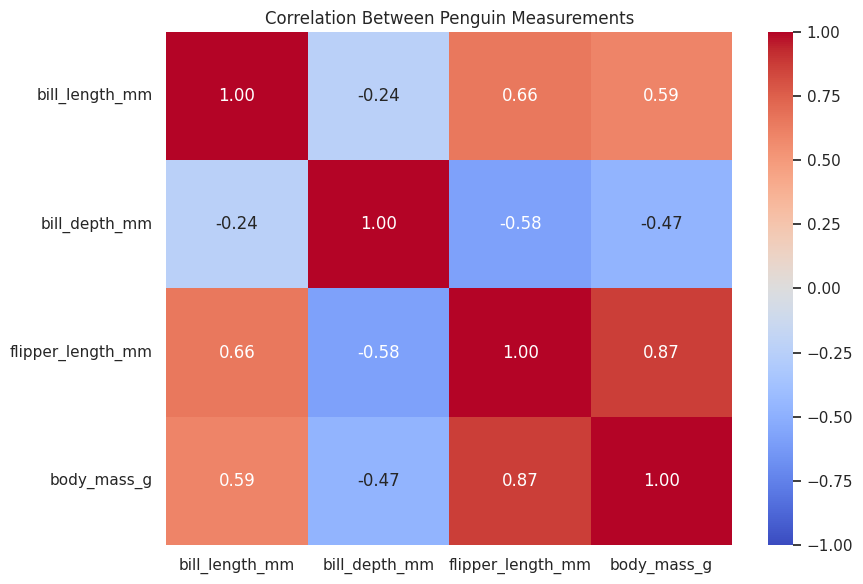

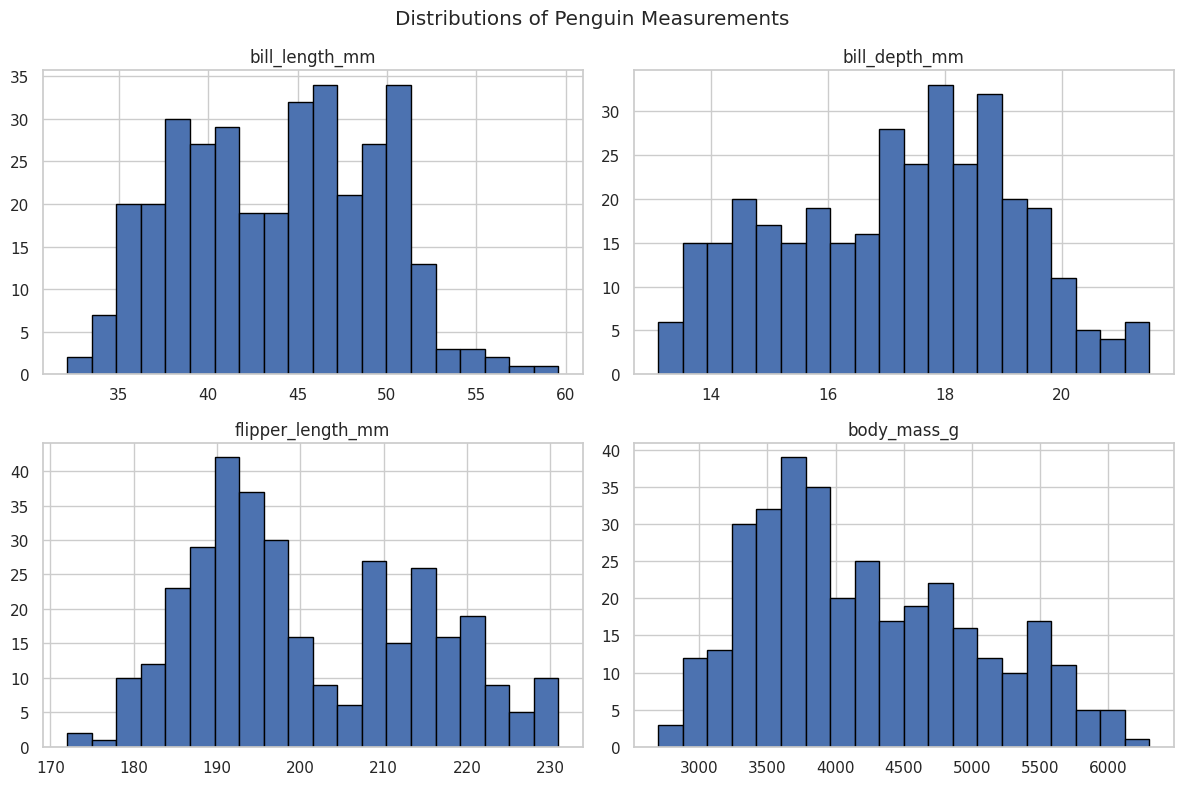

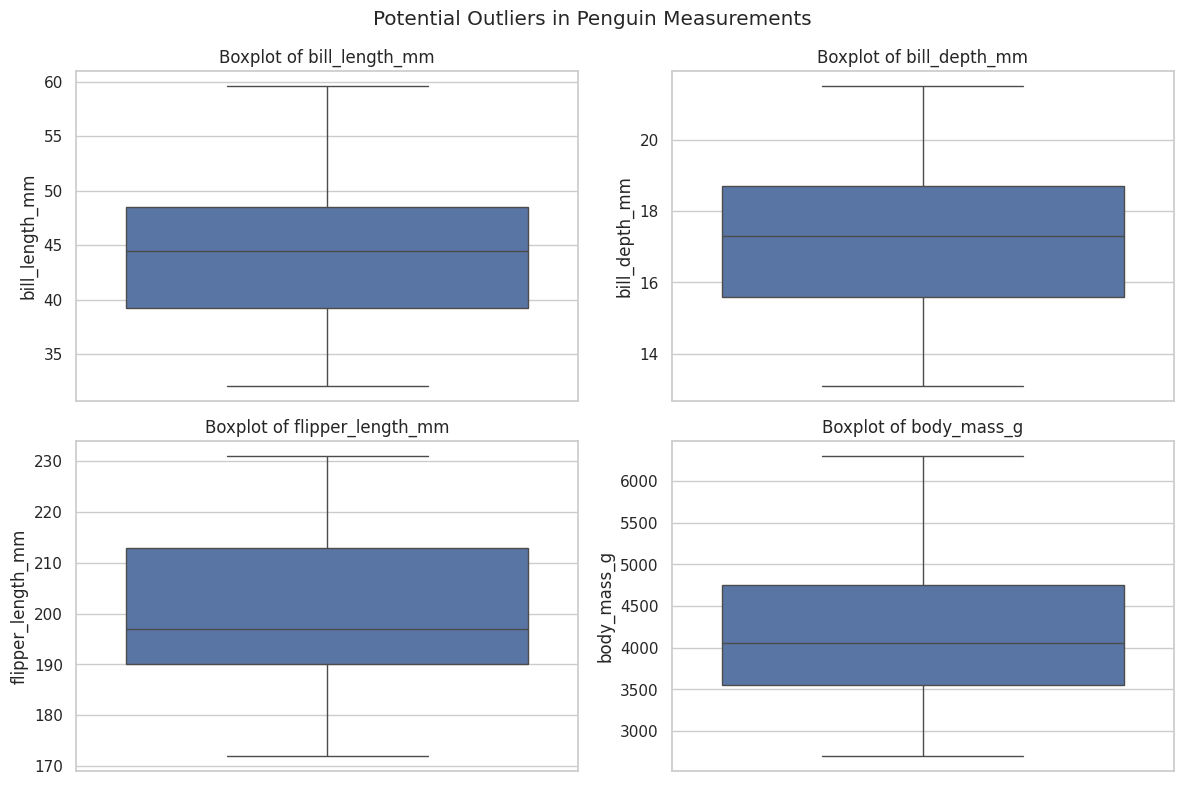

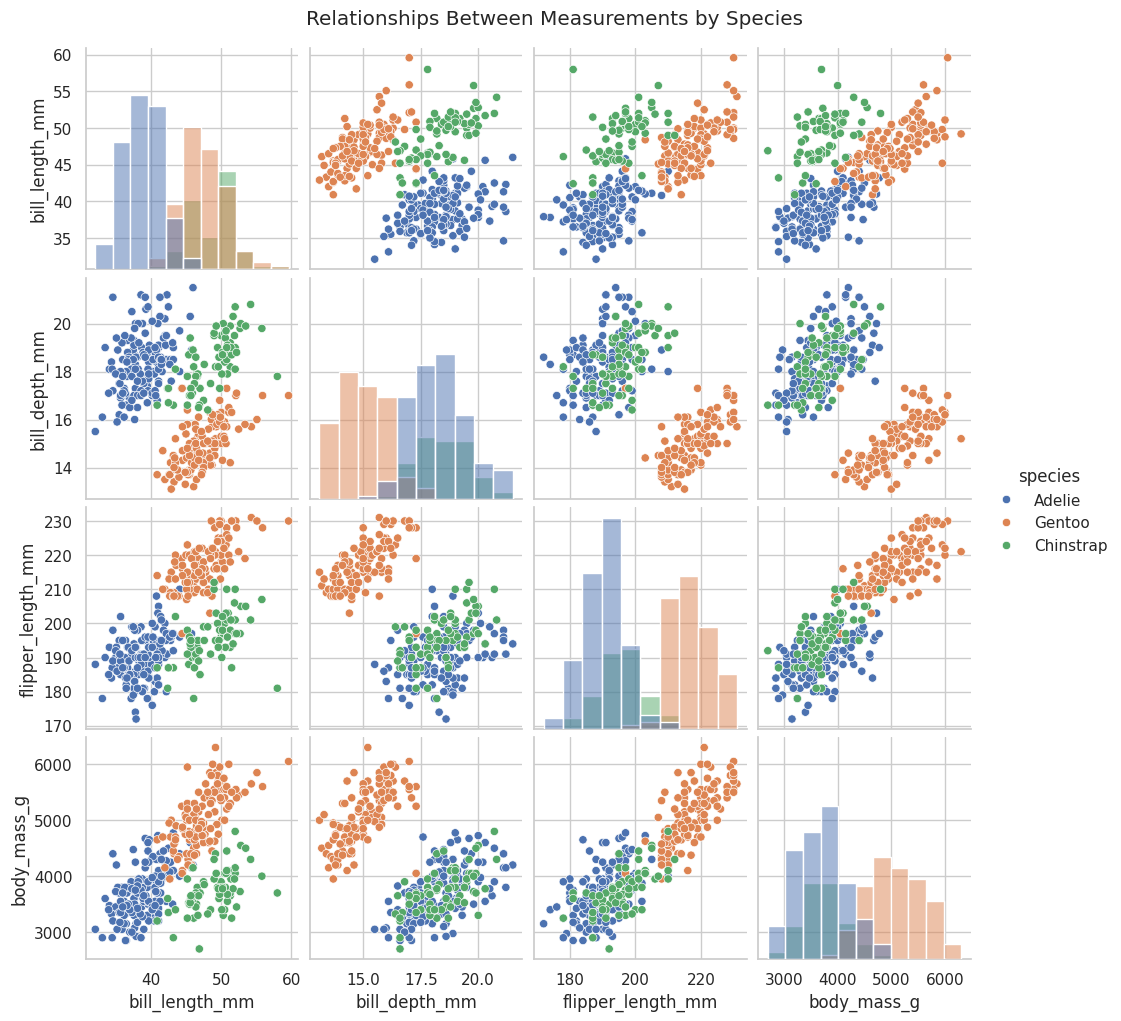

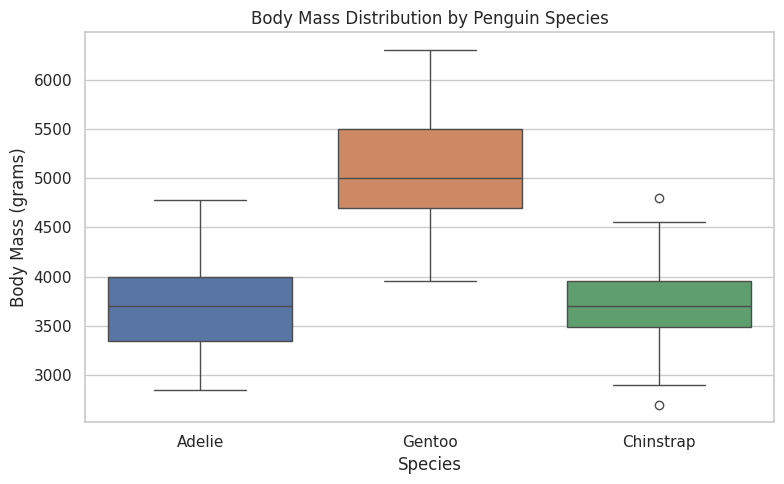

Success! All five visualizations have been generated.


In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# 1. Correlation heatmap
plt.figure(figsize=(9, 6))
corr = df_clean[features].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/correlation_heatmap.png", dpi=300)
plt.show()

# 2. Feature distributions
df_clean[features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/feature_distributions.png", dpi=300)
plt.show()

# 3. Boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df_clean, y=feature, ax=ax)
    ax.set_title(f"Boxplot of {feature}")
    ax.set_ylabel(feature)
plt.suptitle("Potential Outliers in Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/boxplots.png", dpi=300)
plt.show()

# 4. Pairwise scatter plots
pair_plot = sns.pairplot(df_clean, vars=features, hue="species", diag_kind="hist")
pair_plot.figure.suptitle("Relationships Between Measurements by Species", y=1.02)
pair_plot.savefig("/content/pairwise_scatter_plots.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Body mass by species
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="species", y="body_mass_g", hue="species", legend=False)
plt.title("Body Mass Distribution by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.savefig("/content/body_mass_by_species.png", dpi=300)
plt.show()

print("Success! All five visualizations have been generated.")


In [12]:
df = pd.read_csv("/content/penguins.csv")
df_clean = df.copy()

for col in df_clean.select_dtypes(include="number").columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include="object").columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Dataset ready:", df_clean.shape)
print("Missing values remaining:", df_clean.isnull().sum().sum())

Dataset ready: (344, 8)
Missing values remaining: 0


In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("CSV files:", [f for f in os.listdir("/content") if f.endswith(".csv")])


CSV files: ['penguins.csv']


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("/content/penguins.csv")

# Create the cleaned dataset
df_clean = df.copy()

# Fill missing numeric values with the median
numeric_cols = df_clean.select_dtypes(include="number").columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with the mode
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("Dataset loaded and cleaned successfully!")
print("Shape:", df_clean.shape)
print("Missing values remaining:", df_clean.isnull().sum().sum())

FileNotFoundError: [Errno 2] No such file or directory: '/content/penguins.csv'

In [7]:

# Use the cleaned dataset for visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Correlation heatmap
plt.figure(figsize=(9, 6))
corr = df_clean.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Penguin Features")
plt.tight_layout()
plt.savefig("/content/correlation_heatmap.png", dpi=300)
plt.show()

# 2. Feature distributions
df_clean[[
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]].hist(figsize=(12, 8), bins=20, edgecolor="black")

plt.suptitle("Distributions of Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/feature_distributions.png", dpi=300)
plt.show()

# 3. Boxplots for detecting potential outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df_clean, y=feature, ax=ax)
    ax.set_title(f"Boxplot of {feature}")
    ax.set_ylabel(feature)

plt.suptitle("Potential Outliers in Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/boxplots.png", dpi=300)
plt.show()

# 4. Pairwise scatter plots
pair_plot = sns.pairplot(
    df_clean,
    vars=features,
    hue="species",
    diag_kind="hist"
)
pair_plot.figure.suptitle(
    "Pairwise Relationships by Penguin Species",
    y=1.02
)
pair_plot.savefig(
    "/content/pairwise_scatter_plots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 5. Body mass comparison by species
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    legend=False
)
plt.title("Body Mass Distribution by Species")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.savefig("/content/body_mass_by_species.png", dpi=300)
plt.show()

print("All five visualization tasks completed!")


NameError: name 'df_clean' is not defined

<Figure size 900x600 with 0 Axes>

In [ ]:

# Use the cleaned dataset for visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Correlation heatmap
plt.figure(figsize=(9, 6))
corr = df_clean.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Penguin Features")
plt.tight_layout()
plt.savefig("/content/correlation_heatmap.png", dpi=300)
plt.show()

# 2. Feature distributions
df_clean[[
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]].hist(figsize=(12, 8), bins=20, edgecolor="black")

plt.suptitle("Distributions of Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/feature_distributions.png", dpi=300)
plt.show()

# 3. Boxplots for detecting potential outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df_clean, y=feature, ax=ax)
    ax.set_title(f"Boxplot of {feature}")
    ax.set_ylabel(feature)

plt.suptitle("Potential Outliers in Penguin Measurements")
plt.tight_layout()
plt.savefig("/content/boxplots.png", dpi=300)
plt.show()

# 4. Pairwise scatter plots
pair_plot = sns.pairplot(
    df_clean,
    vars=features,
    hue="species",
    diag_kind="hist"
)
pair_plot.figure.suptitle(
    "Pairwise Relationships by Penguin Species",
    y=1.02
)
pair_plot.savefig(
    "/content/pairwise_scatter_plots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 5. Body mass comparison by species
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    legend=False
)
plt.title("Body Mass Distribution by Species")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.savefig("/content/body_mass_by_species.png", dpi=300)
plt.show()

print("All five visualization tasks completed!")


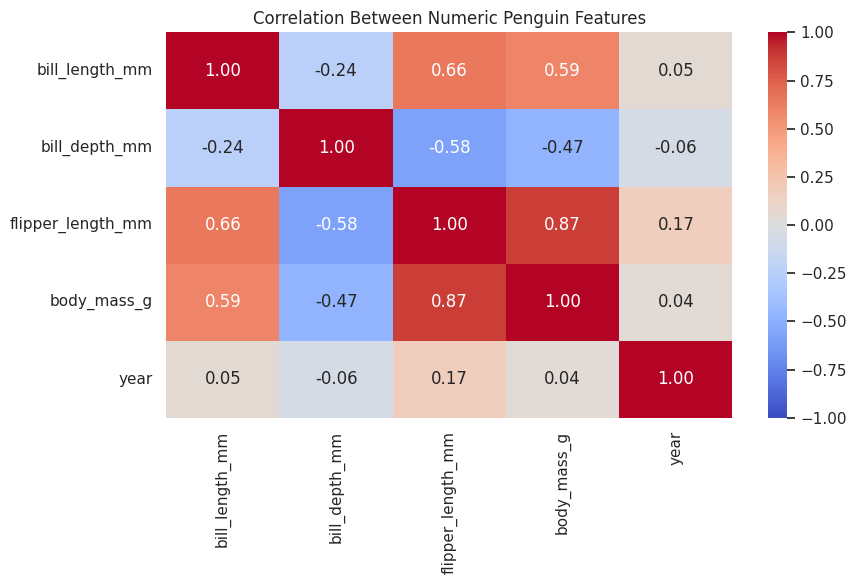

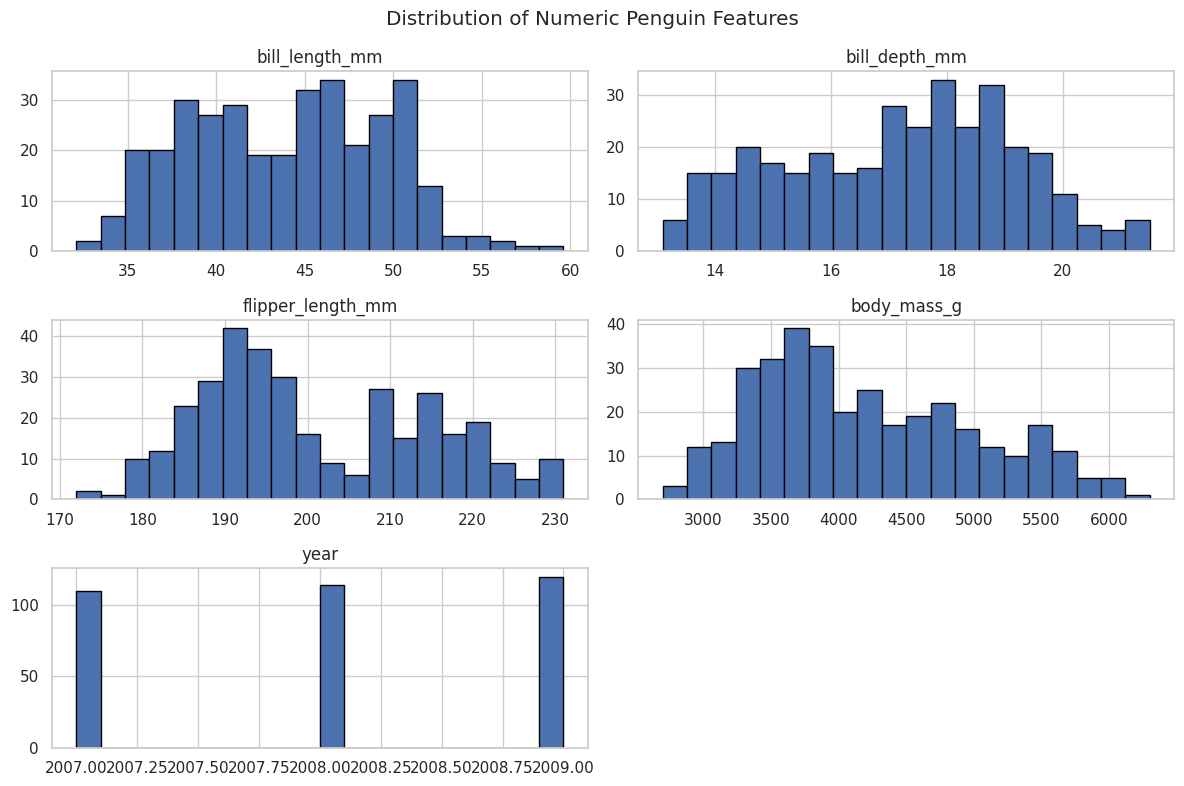

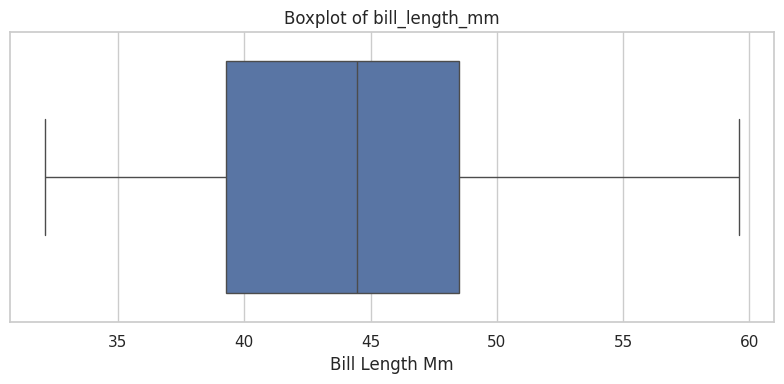

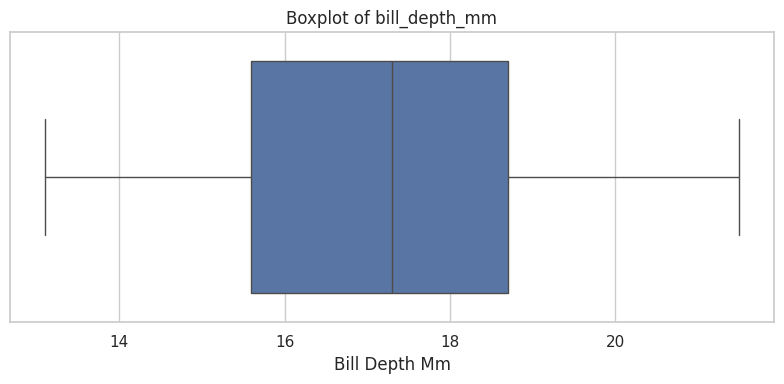

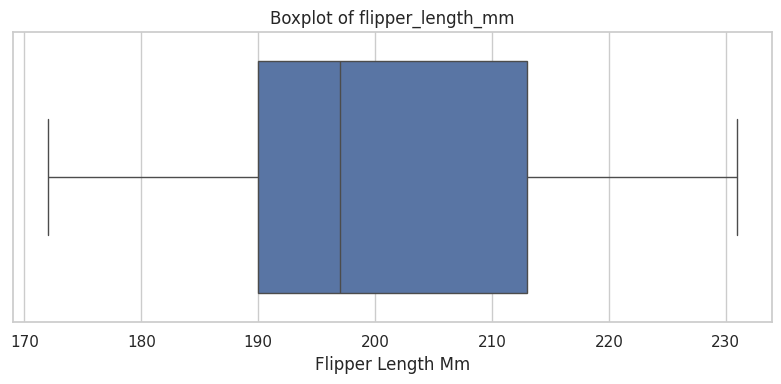

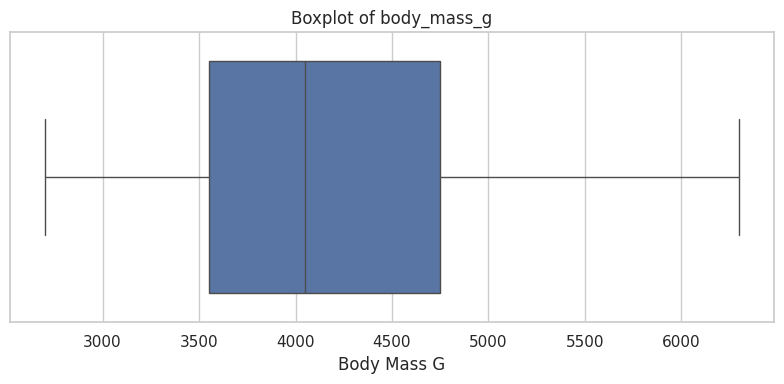

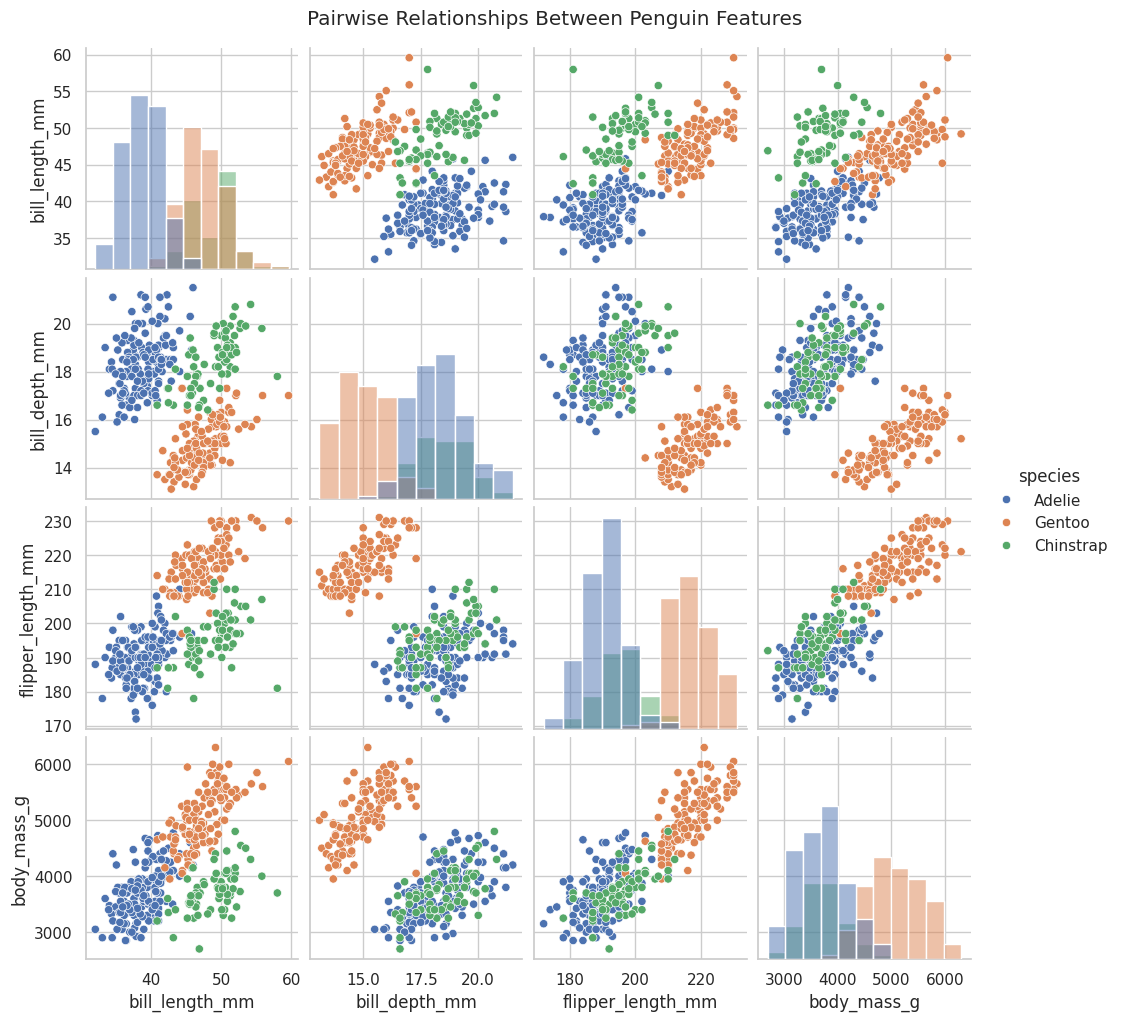

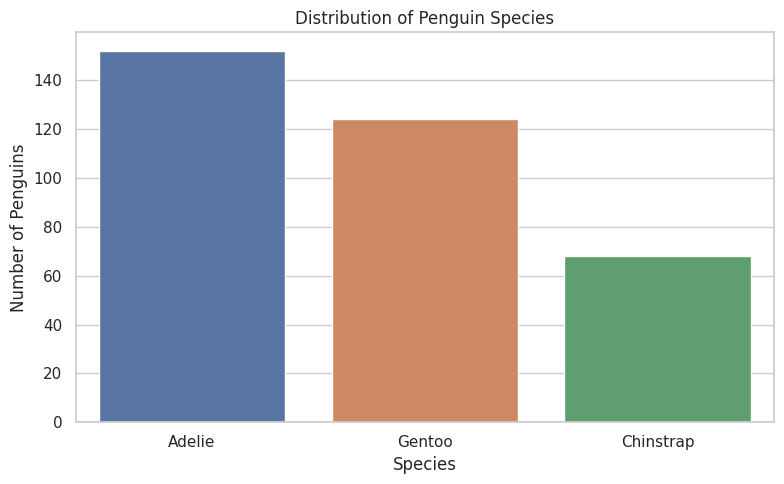

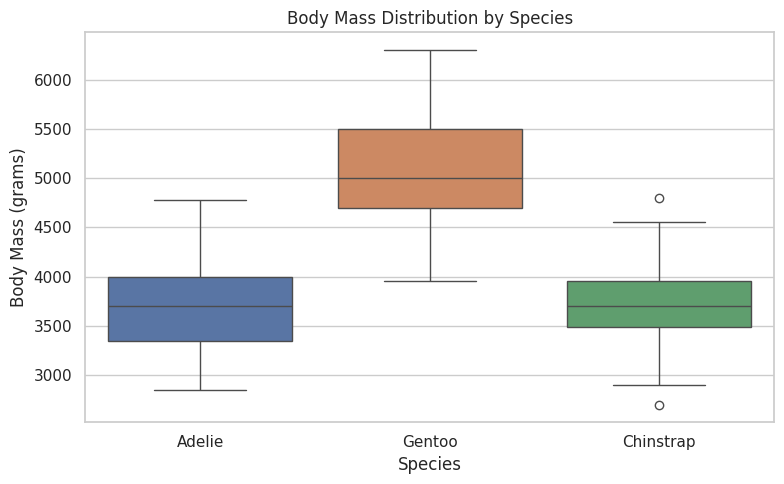

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Correlation heatmap
plt.figure(figsize=(9, 6))
correlation = df_clean.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numeric Penguin Features")
plt.tight_layout()
plt.show()


# 2. Feature distributions
numeric_cols = df_clean.select_dtypes(include="number").columns

df_clean[numeric_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Penguin Features")
plt.tight_layout()
plt.show()


# 3. Boxplots to examine spread and potential outliers
for col in ["bill_length_mm", "bill_depth_mm",
            "flipper_length_mm", "body_mass_g"]:

    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df_clean, x=col)

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col.replace("_", " ").title())

    plt.tight_layout()
    plt.show()


# 4. Pairwise scatter plots
pairplot = sns.pairplot(
    df_clean,
    vars=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    hue="species",
    diag_kind="hist"
)

pairplot.figure.suptitle(
    "Pairwise Relationships Between Penguin Features",
    y=1.02
)

plt.show()


# 5. Species distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="species",
    hue="species",
    legend=False
)

plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.tight_layout()
plt.show()


# 6. Body mass by species
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    legend=False
)

plt.title("Body Mass Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.show()



In [ ]:
# Make a copy so the original dataset remains unchanged
df_clean = df.copy()

# Fill missing numeric values with their median
numeric_cols = df_clean.select_dtypes(include="number").columns

for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

# Fill missing categorical values with their mode
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode()

        if not mode_value.empty:
            df_clean[col] = df_clean[col].fillna(
                mode_value.iloc[0]
            )

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

# Save the cleaned dataset
df_clean.to_csv("/content/penguins_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")


Missing values before cleaning:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Missing values after cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

Cleaned dataset shape: (344, 8)

Cleaned dataset saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_csv("/content/penguins.csv")

print("Dataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Dataset shape: (344, 8)

Column data types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

Missing values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,344.0,NaN,NaN,NaN,2008.02907,0.818356,2007.0,2007.0,2008.0,2009.0,2009.0


In [ ]:
!pip install pandas matplotlib seaborn


In [ ]:
import pandas as pd

df = pd.read_csv("/content/penguins.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
